# Supplementary Figure S2. Agreement between FastRNA and independent annotators

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

import hashlib
import inspect
import pickle
from functools import lru_cache

REFRESH = False
CACHE_DIR = ROOT / ".cache" / "figS2"


def _input_key():
    h = hashlib.sha1()
    for path in sorted(data_file("comparison").rglob("*")):
        if path.is_file():
            st = path.stat()
            h.update(f"{path.relative_to(ROOT)}|{st.st_size}|{st.st_mtime_ns}".encode())
    return h.hexdigest()[:12]


INPUT_KEY = _input_key()


def disk_cache(fn):
    try:
        src = inspect.getsource(fn)
    except (OSError, TypeError):
        src = fn.__code__.co_code.hex()
    path = CACHE_DIR / f"{fn.__name__}-{INPUT_KEY}-{hashlib.sha1(src.encode()).hexdigest()[:8]}.pkl"

    @lru_cache(maxsize=1)
    def wrapper():
        if path.exists() and not REFRESH:
            return pickle.loads(path.read_bytes())
        out = fn()
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.write_bytes(pickle.dumps(out))
        return out
    return wrapper


def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Shared tool-comparison helpers

In [2]:
from functools import lru_cache
from itertools import combinations
from matplotlib.colors import Normalize


def _heatmap(ax, matrix, label, vmin, vmax, fig=None, cax=None):
    cmap = plt.cm.Blues.copy()
    cmap.set_bad("0.90")
    im = ax.imshow(matrix.to_numpy(float), cmap=cmap, norm=Normalize(vmin, vmax))
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    finish(ax)
    ax.tick_params(length=0)
    hi = vmin + 0.62 * (vmax - vmin)
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            v = matrix.iat[r, c]
            if np.isnan(v):
                ax.text(c, r, "n/a", ha="center", va="center", fontsize=6, color="0.40")
            else:
                ax.text(c, r, "1" if v >= 0.995 else f"{v:.2f}"[1:], ha="center",
                        va="center", fontsize=6, color="white" if v > hi else "0.15")
    if cax is not None:
        p = cax.get_position()
        horizontal = p.width * (fig or ax.figure).get_size_inches()[0] > \
            p.height * (fig or ax.figure).get_size_inches()[1]
        cb = (fig or ax.figure).colorbar(im, cax=cax,
                                         orientation="horizontal" if horizontal else "vertical")
        if horizontal:
            cax.xaxis.set_ticks_position("top")
            cax.xaxis.set_label_position("top")
    else:
        cb = (fig or ax.figure).colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(label)
    cb.outline.set_visible(False)
    return im

MATRIX_TOOLS = ["parse", "dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
MATRIX_LABELS = ["FastRNA", "DSSR", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]
JSON_PAIR_FILES = {
    "parse": "comparison/parse_pairs.json",
    "dssr": "comparison/dssr_pairs.json",
    "rnaview": "comparison/rnaview_pairs.json",
    "barnaba": "comparison/barnaba_pairs.json",
    "rnapolis": "comparison/rnapolis_pairs.json",
    "bpnet": "comparison/bpnet_pairs.json",
}
_NUM = __import__("re").compile(r"^(-?\d+)([A-Za-z]?)$")
UNCLASSIFIED = "?"


def _residue(chain, number, icode=""):
    m = _NUM.match(str(number))
    if not chain or m is None:
        raise ValueError(f"uncanonicalizable residue id: {chain!r} {number!r}")
    appended = m.group(2)
    if appended and icode:
        raise ValueError(f"two insertion codes: {chain!r} {number!r} {icode!r}")
    return (str(chain), int(m.group(1)), icode or appended)


def _flip(lw):
    if lw == UNCLASSIFIED:
        return lw
    if lw.startswith("n"):
        return "n" + _flip(lw[1:])
    if len(lw) != 3:
        return lw
    return lw[0] + lw[2] + lw[1]


def _flip_label(label):
    return "|".join(_flip(part) for part in label.split("|"))


def _pair_entry(res1, res2, label):
    if res2 < res1:
        return (res2, res1), _flip_label(label)
    return (res1, res2), label


def _adjacent(res1, res2):
    return res1[0] == res2[0] and abs(res1[1] - res2[1]) == 1


def _ingest(rows):
    pairs = {}
    for res1, res2, label in rows:
        if _adjacent(res1, res2):
            continue
        key, canonical_label = _pair_entry(res1, res2, label)
        pairs.setdefault(key, set()).add(canonical_label)
    return pairs


def _load_json_pairs(tool):
    raw = _json(JSON_PAIR_FILES[tool])
    out = {}
    for pdb, record in raw.items():
        if record.get("status") != "ok":
            continue
        rows = []
        for row in record["pairs"]:
            c1, n1, c2, n2, lw = row[:5]
            rows.append((_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED))
        out[pdb] = _ingest(rows)
    return out


def _hub_unit(unit):
    fields = unit.split("|")
    if len(fields) < 5 or fields[1] != "1":
        return None
    icode = fields[7] if len(fields) >= 8 else ""
    return _residue(fields[2], fields[4], icode)


def _load_fr3d_pairs():
    out = {}
    for csv_path in sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv")):
        rows = []
        for line in csv_path.read_text(errors="replace").splitlines():
            if not line.strip():
                continue
            fields = [part.strip().strip('"') for part in line.split('\",\"')]
            if len(fields) != 3:
                continue
            res1, res2 = _hub_unit(fields[0]), _hub_unit(fields[2])
            if res1 is not None and res2 is not None:
                rows.append((res1, res2, fields[1]))
        out[csv_path.stem] = _ingest(rows)
    return out


@lru_cache(maxsize=1)
def _load_all_pairsets():
    pairsets = {tool: _load_json_pairs(tool) for tool in JSON_PAIR_FILES}
    pairsets["fr3d"] = _load_fr3d_pairs()
    return pairsets


def _single_family(labels):
    if any("|" in lw for lw in labels):
        return None
    fams = {lw for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None


def _single_family_units(pairsets_by_pdb):
    units = {}
    for pdb, pairsets in pairsets_by_pdb.items():
        for key, labels in pairsets.items():
            fam = _single_family(labels)
            if fam is not None:
                units[(pdb, key)] = fam
    return units


def _canon_lw(lw):
    order = {"W": 0, "H": 1, "S": 2}
    return lw[0] + lw[2] + lw[1] if order[lw[1]] > order[lw[2]] else lw


WATSON_CRICK = {frozenset("GC"), frozenset("AU")}


@lru_cache(maxsize=1)
def _residue_names():
    return _json("comparison/residue_names.json")


def _is_canonical(pdb, key, labels):
    names = _residue_names().get(pdb, {})
    bases = [names.get(f"{chain}|{num}|{icode}") for chain, num, icode in key]
    if None in bases or frozenset(bases) not in WATSON_CRICK:
        return False
    return any(part == "cWW" for lw in labels for part in lw.split("|"))


@lru_cache(maxsize=1)
def _parse_candidates():
    raw = _json("comparison/parse_candidates.json")
    return {pdb: _ingest([(_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED)
                          for c1, n1, c2, n2, lw, _ in rec["pairs"]])
            for pdb, rec in raw.items() if pdb != "_meta"}


@lru_cache(maxsize=1)
def fastrna_credited(partner):
    pairsets, candidates = _load_all_pairsets(), _parse_candidates()
    out = {}
    for pdb, ours in pairsets["parse"].items():
        theirs = pairsets[partner].get(pdb, {})
        extra = {k: v for k, v in candidates.get(pdb, {}).items()
                 if k in theirs and k not in ours and UNCLASSIFIED not in v}
        out[pdb] = {**ours, **extra}
    return out


def _pair_lists(a, b):
    pairsets = _load_all_pairsets()
    pa = fastrna_credited(b) if a == "parse" else pairsets[a]
    pb = fastrna_credited(a) if b == "parse" else pairsets[b]
    return pa, pb


def _empty_matrix():
    return pd.DataFrame(np.eye(len(MATRIX_LABELS)), index=MATRIX_LABELS, columns=MATRIX_LABELS)


@disk_cache
def noncanonical_detection_matrix():
    pairsets = _load_all_pairsets()
    mat = _empty_matrix()
    for (a, la), (b, lb) in combinations(zip(MATRIX_TOOLS, MATRIX_LABELS), 2):
        inter = union = 0
        list_a, list_b = _pair_lists(a, b)
        for pdb in list_a.keys() & list_b.keys():
            pa, pb = list_a[pdb], list_b[pdb]
            for key in pa.keys() | pb.keys():
                labels = pa.get(key, set()) | pb.get(key, set())
                if any("|" in lw for lw in labels) or _is_canonical(pdb, key, labels):
                    continue
                union += 1
                inter += key in pa and key in pb
        mat.loc[la, lb] = mat.loc[lb, la] = inter / union
    return mat


@disk_cache
def noncanonical_kappa_matrix():
    pairsets = _load_all_pairsets()
    units = {tool: _single_family_units(pairsets[tool]) for tool in MATRIX_TOOLS}
    mat = _empty_matrix()
    for (a, la), (b, lb) in combinations(zip(MATRIX_TOOLS, MATRIX_LABELS), 2):
        n = agree = 0
        c1, c2 = Counter(), Counter()
        list_a, list_b = _pair_lists(a, b)
        ua = units[a] if a != "parse" else _single_family_units(list_a)
        ub = units[b] if b != "parse" else _single_family_units(list_b)
        for (pdb, key), x in ua.items():
            y = ub.get((pdb, key))
            if y is None or _is_canonical(pdb, key, {x, y}):
                continue
            n += 1
            agree += x == y
            c1[x] += 1
            c2[y] += 1
        po, pe = agree / n, sum(c1[k] * c2[k] for k in c1) / n ** 2
        mat.loc[la, lb] = mat.loc[lb, la] = (po - pe) / (1 - pe)
    return mat


## Source data for A-B

In [3]:
import sys
import importlib
sys.path.insert(0, str(ROOT / "scripts" / "validation"))
import figure2_comparison as _comparison
_comparison = importlib.reload(_comparison)

SOURCE_DATA = ROOT / "figures" / "source_data"
SOURCE_DATA.mkdir(parents=True, exist_ok=True)
noncanonical_detection_matrix().to_csv(SOURCE_DATA / "figS2_detection_matrix.csv")
noncanonical_kappa_matrix().to_csv(SOURCE_DATA / "figS2_classification_kappa.csv")

# Free the pair data before Comparison loads its own copy, so the two are never
# held at once (peak memory matters on the CI runner).
import gc
for _f in (fastrna_credited, _load_all_pairsets, _parse_candidates):
    _f.cache_clear()
gc.collect()


@disk_cache
def candidate_credit_detection():
    comparison = _comparison.Comparison(ROOT / "data")
    credit_rows = []
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        for stage in ("selected", "credited"):
            pdbs, shared, union, excluded = comparison.detection_counts("parse", tool, stage)
            for k, kind in enumerate(("canonical", "non-canonical")):
                intersection, denominator = shared[:, k].sum(), union[:, k].sum()
                credit_rows.append({"tool": label, "stage": stage, "kind": kind,
                                    "structures": len(pdbs), "intersection": int(intersection),
                                    "union": int(denominator), "jaccard": intersection / denominator})
    return pd.DataFrame(credit_rows)


candidate_credit_detection().to_csv(SOURCE_DATA / "figS2_candidate_credit_detection.csv", index=False)
# Comparison caches its methods with lru_cache, which keeps the object alive.
_comparison.Comparison.tool.cache_clear()
_comparison.Comparison.credited.cache_clear()
gc.collect()

0

## Panel A
Non-canonical base-pair detection agreement between every pair of tools (Jaccard)

          FastRNA   DSSR   FR3D  RNAView  barnaba  RNApolis  BPNET
FastRNA     1.000  0.869  0.626    0.599    0.621     0.575  0.665
DSSR        0.869  1.000  0.541    0.599    0.634     0.545  0.587
FR3D        0.626  0.541  1.000    0.426    0.420     0.544  0.692
RNAView     0.599  0.599  0.426    1.000    0.518     0.470  0.449
barnaba     0.621  0.634  0.420    0.518    1.000     0.465  0.467
RNApolis    0.575  0.545  0.544    0.470    0.465     1.000  0.604
BPNET       0.665  0.587  0.692    0.449    0.467     0.604  1.000


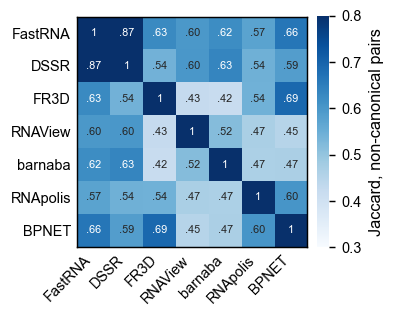

In [4]:
print(noncanonical_detection_matrix().round(3))


def draw_a(ax, fig=None, cax=None):
    _heatmap(ax, noncanonical_detection_matrix(), "Jaccard, non-canonical pairs", 0.3, 0.8, fig, cax)


fig, ax = plt.subplots(figsize=(3.0, 2.6))
draw_a(ax, fig)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_A_noncanonical_detection.png")
plt.show()


## Panel B
Cohen's kappa on the LW class of non-canonical pairs both tools detect, every pair of tools

          FastRNA   DSSR   FR3D  RNAView  barnaba  RNApolis  BPNET
FastRNA     1.000  0.949  0.971    0.900    0.760     0.855  0.956
DSSR        0.949  1.000  0.917    0.890    0.743     0.854  0.939
FR3D        0.971  0.917  1.000    0.935    0.762     0.792  0.966
RNAView     0.900  0.890  0.935    1.000    0.709     0.826  0.951
barnaba     0.760  0.743  0.762    0.709    1.000     0.725  0.777
RNApolis    0.855  0.854  0.792    0.826    0.725     1.000  0.832
BPNET       0.956  0.939  0.966    0.951    0.777     0.832  1.000


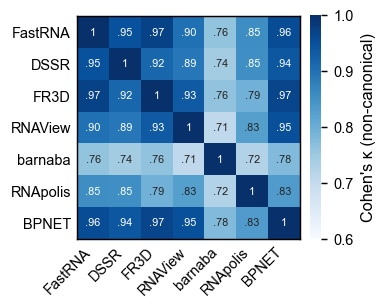

In [5]:
print(noncanonical_kappa_matrix().round(3))


def draw_b(ax, fig=None, cax=None):
    _heatmap(ax, noncanonical_kappa_matrix(), "Cohen's \u03ba (non-canonical)", 0.6, 1.0, fig, cax)


fig, ax = plt.subplots(figsize=(3.0, 2.6))
draw_b(ax, fig)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_B_noncanonical_kappa.png")
plt.show()


## Panel C
LW-class agreement with FastRNA, per class and tool

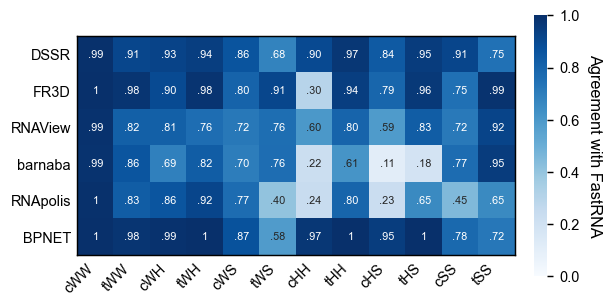

In [6]:
@disk_cache
def class_agreement_with_fastrna():
    pairsets = _load_all_pairsets()
    units = {tool: {k: _canon_lw(v) for k, v in _single_family_units(pairsets[tool]).items()}
             for tool in MATRIX_TOOLS}
    rows = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        ours = {k: _canon_lw(v) for k, v in _single_family_units(fastrna_credited(tool)).items()}
        theirs = units[tool]
        both, either = Counter(), Counter()
        for key in ours.keys() & theirs.keys():
            a, b = ours[key], theirs[key]
            either[a] += 1
            if a == b:
                both[a] += 1
            else:
                either[b] += 1
        rows[label] = {lw: both[lw] / either[lw] if either[lw] else np.nan for lw in LW}
        print(f"{label:9s} smallest class: {min(either[lw] for lw in LW):,} pairs")
    return pd.DataFrame(rows).T


def draw_c(ax, fig=None, cax=None):
    im = _heatmap(ax, class_agreement_with_fastrna(), "Agreement with FastRNA", 0.0, 1.0, fig, cax)
    im.colorbar.ax.set_ylabel("Agreement with FastRNA", rotation=270, va="bottom")

fig, ax = plt.subplots(figsize=(4.8, 2.5))
draw_c(ax, fig)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_C_class_agreement.png")
plt.show()


## Panel D
Independent-tool support in FastRNA-DSSR class conflicts

          P (cluster-robust) significance
FR3D            0.000000e+00         ****
RNAView         0.000000e+00         ****
barnaba         0.000000e+00         ****
RNApolis        7.756057e-01         n.s.
BPNet          4.840938e-128         ****


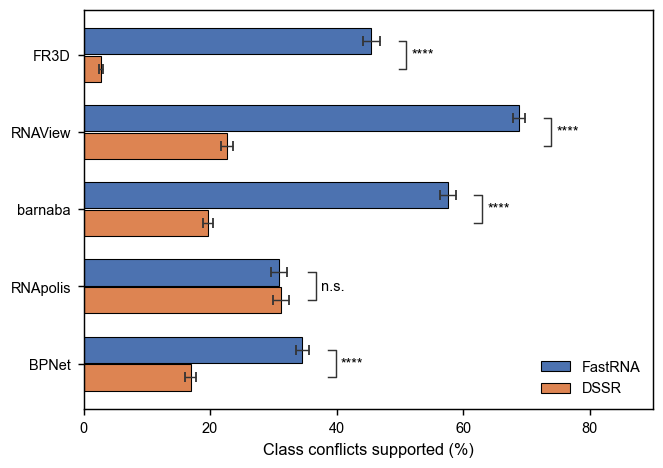

In [7]:
REFEREES = ["fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
REFEREE_LABELS = ["FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]
SHARED = _json("validation/annotator_consensus_shared.json")

from scipy.stats import norm


def stars(p):
    return ("****" if p < 0.0001 else "***" if p < 0.001 else "**" if p < 0.01
            else "*" if p < 0.05 else "n.s.")


def referee_p(tool):
    n, a, b = np.array(list(SHARED["per_structure"][tool].values()), float).T
    diff = (a - b).sum() / n.sum()
    u = (a - b - diff * n) / n.sum()
    G = len(u)
    se = np.sqrt(G / (G - 1) * (u ** 2).sum())
    return 2 * norm.sf(abs(diff / se))


def referee_ci(tool, reps=2000, seed=7):
    n, a, b = np.array(list(SHARED["per_structure"][tool].values()), float).T
    rng = np.random.default_rng(seed)
    w = np.array([np.bincount(rng.integers(0, len(n), len(n)), minlength=len(n))
                  for _ in range(reps)], float)
    return {side: np.percentile(100 * (w @ v) / (w @ n), [2.5, 97.5])
            for side, v in (("parse", a), ("dssr", b))}


REFEREE_CI = {t: referee_ci(t) for t in REFEREES}
REFEREE_P = pd.DataFrame({"P (cluster-robust)": [referee_p(t) for t in REFEREES]},
                         index=REFEREE_LABELS)
REFEREE_P["significance"] = REFEREE_P["P (cluster-robust)"].map(stars)
print(REFEREE_P)

_per = SHARED["per_annotator"]
_src = pd.DataFrame({
    "conflicts covered": [_per[f"class_disagreement|{t}|covered"] for t in REFEREES],
    "supports FastRNA": [_per[f"class_disagreement|{t}|votes_parse"] for t in REFEREES],
    "supports DSSR": [_per.get(f"class_disagreement|{t}|votes_dssr", 0) for t in REFEREES],
}, index=pd.Index(REFEREE_LABELS, name="referee"))
_src["supports FastRNA (%)"] = 100 * _src["supports FastRNA"] / _src["conflicts covered"]
_src["supports DSSR (%)"] = 100 * _src["supports DSSR"] / _src["conflicts covered"]
for side, name in (("parse", "FastRNA"), ("dssr", "DSSR")):
    _src[f"supports {name} 95% CI low (%)"] = [REFEREE_CI[t][side][0] for t in REFEREES]
    _src[f"supports {name} 95% CI high (%)"] = [REFEREE_CI[t][side][1] for t in REFEREES]
_src = _src.join(REFEREE_P)
(ROOT / "figures" / "source_data").mkdir(parents=True, exist_ok=True)
_src.to_csv(ROOT / "figures" / "source_data" / "figS2_D_class_conflicts.csv")


def draw_d(ax, compact=False):
    per = SHARED["per_annotator"]
    rate = lambda t, f: 100 * per.get(f"class_disagreement|{t}|{f}", 0) / per[f"class_disagreement|{t}|covered"]
    y = np.arange(len(REFEREES))[::-1]
    parse_vals = np.array([rate(t, "votes_parse") for t in REFEREES])
    dssr_vals = np.array([rate(t, "votes_dssr") for t in REFEREES])
    ax.barh(y + 0.18, parse_vals, height=0.34, color=BLUE, label="FastRNA", edgecolor="black", linewidth=0.6)
    ax.barh(y - 0.18, dssr_vals, height=0.34, color=ORANGE, label="DSSR", edgecolor="black", linewidth=0.6)
    hi = {}
    for off, side, vals in ((0.18, "parse", parse_vals), (-0.18, "dssr", dssr_vals)):
        lo_hi = np.array([REFEREE_CI[t][side] for t in REFEREES])
        ax.errorbar(vals, y + off, xerr=[vals - lo_hi[:, 0], lo_hi[:, 1] - vals], fmt="none",
                    ecolor="0.2", capsize=2.5, lw=0.8)
        hi[side] = lo_hi[:, 1]
    for yy, ph, dh, label in zip(y, hi["parse"], hi["dssr"], REFEREE_LABELS):
        x = max(ph, dh) + 3
        ax.plot([x, x + 1.2, x + 1.2, x], [yy - 0.18, yy - 0.18, yy + 0.18, yy + 0.18],
                color="0.2", lw=0.8)
        ax.text(x + 2.0, yy, REFEREE_P.loc[label, "significance"], ha="left", va="center",
                fontsize=8)
    ax.set_yticks(y, REFEREE_LABELS)
    ax.set_xlim(0, 90)
    ax.set_xticks([0, 20, 40, 60, 80])
    ax.set_xlabel("Class conflicts supported (%)")
    if compact:
        ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2,
                  handlelength=1.0, handletextpad=0.3, columnspacing=1.2,
                  borderaxespad=0.0, borderpad=0.0)
    else:
        ax.legend(loc="lower right")
    finish(ax)


def seat_legend(ax, gap_pt=0.2):
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    leg = ax.get_legend()
    lowest = min(h.get_window_extent(r).y0 for h in leg.legend_handles)
    for t in leg.get_texts():
        _, _, descent = r.get_text_width_height_descent(t.get_text(), t.get_fontproperties(),
                                                        ismath=False)
        lowest = min(lowest, t.get_window_extent(r).y0 + descent)
    frame_top = (ax.get_window_extent(r).y1
                 + (ax.spines["top"].get_linewidth() / 2 + gap_pt) * fig.dpi / 72)
    dy = (lowest - frame_top) / ax.get_window_extent(r).height
    x, y = leg.get_bbox_to_anchor().transformed(ax.transAxes.inverted()).p0
    leg.set_bbox_to_anchor((x, y - dy), transform=ax.transAxes)

fig, ax = plt.subplots(figsize=(5.2, 3.7))
draw_d(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_D_class_conflicts.png")
plt.show()


## Panel E
Share of each annotator's non-canonical pairs that none of the other six report

          unsupported     pairs
FastRNA          0.20  306529.0
BPNET            0.52  266558.0
FR3D             0.82  241068.0
DSSR             2.41  389879.0
RNApolis        12.85  349061.0
barnaba         21.49  524718.0
RNAView         23.63  533540.0


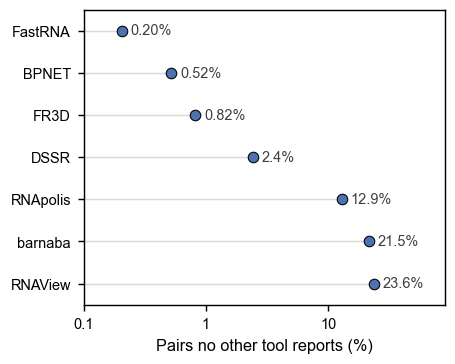

In [8]:
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

SUPPORT = _json("validation/tool_support_profile.json")


def unsupported_share():
    rows = {}
    for tool in SUPPORT["tools"].values():
        nc = tool["non-canonical"]
        rows[tool["label"]] = {"unsupported": 100 * nc["0"] / sum(nc.values()),
                               "pairs": sum(nc.values())}
    return pd.DataFrame(rows).T.sort_values("unsupported")


print(unsupported_share().round(2))


def draw_e(ax, compact=False):
    d = unsupported_share()
    y = np.arange(len(d))
    ax.hlines(y, 0.1, d["unsupported"], color="0.85", lw=0.8, zorder=1)
    ax.scatter(d["unsupported"], y, s=34, color=BLUE, edgecolors="black",
               linewidths=0.6, zorder=3)
    for yi, v in zip(y, d["unsupported"]):
        label = f"{v:.1f}%" if v >= 1 else f"{v:.2f}%"
        if compact:
            ax.annotate(label, (v, yi), xytext=(5, 0), textcoords="offset points", va="center",
                        ha="left", fontsize=7, color="0.25")
        else:
            ax.text(v * 1.18, yi, label, va="center", ha="left", fontsize=8, color="0.25")
    ax.set_yticks(y, d.index)
    ax.set_ylim(len(d) - 0.5, -0.5)
    ax.set_xscale("log")
    ax.set_xlim(0.1, 400 if compact else 90)
    ax.xaxis.set_major_locator(FixedLocator([0.1, 1, 10]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Pairs no other tool reports (%)")
    finish(ax)


fig, ax = plt.subplots(figsize=(3.6, 2.9))
draw_e(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_E_unsupported_pairs.png")
plt.show()


## Panel F
FastRNA's ambiguous pairs per ambiguity type: how often the other tools split between classes, against unambiguous pairs of the two classes (the overall comparison is Fig. 2F)


3,843 ambiguous and 748,260 unambiguous FastRNA pairs in 1,177 structures


,flagged (%),confident (%),bootstrap p,P (cluster-robust),significance
comparison,,,,,
all ambiguous vs family-matched,54.692892,23.800773,< 0.0005,1.211441e-244,****
cHH|cWW,42.691415,24.880942,< 0.0005,8.659346e-22,****
tHH|tWW,67.682927,25.133738,< 0.0005,1.988928e-76,****
cHH|cWH,70.813397,32.022880,< 0.0005,3.927222e-58,****
tHH|tWH,55.942029,28.811854,< 0.0005,6.493023e-24,****
cWH|cWW,39.184953,8.049559,< 0.0005,8.586905e-30,****
tWH|tWW,51.324503,13.314884,< 0.0005,1.779957e-42,****


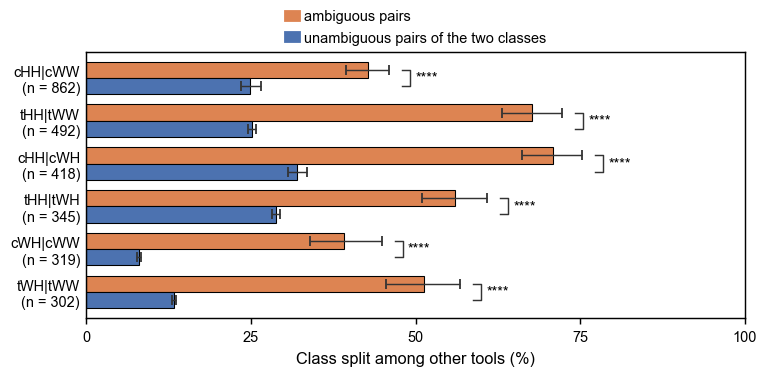

In [9]:
from collections import Counter
canon = _canon_lw
OTHER = ["dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]

def family(labels):
    fams = {canon(lw) for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None

@disk_cache
def votes_table():
    pairsets = _load_all_pairsets()
    rows = []
    for pdb, pairs in pairsets["parse"].items():
        for key, labels in pairs.items():
            amb = [lw for lw in labels if "|" in lw]
            own = None if amb else family(labels)
            if not amb and own is None:
                continue
            opts = tuple(sorted({canon(x) for x in amb[0].split("|")})) if amb else None
            votes = {t: f for t in OTHER
                     if (lab := pairsets[t].get(pdb, {}).get(key)) is not None
                     and (f := family(lab)) is not None}
            rows.append((pdb, bool(amb), own, opts, votes))
    return pd.DataFrame(rows, columns=["pdb", "amb", "own", "opts", "votes"])


V = votes_table().copy()
V["k"] = V.votes.map(len)
V["split"] = V.votes.map(lambda v: len(set(v.values())) > 1)
print(f"{V.amb.sum():,} ambiguous and {(~V.amb).sum():,} unambiguous FastRNA pairs in "
      f"{V.pdb.nunique():,} structures")

E = V[V.k >= 2].reset_index(drop=True)

B_REPS = 2000
pdb_idx, pdbs = pd.factorize(E.pdb)
nP = len(pdbs)

def counts(mask):
    m = np.asarray(mask)
    return (np.bincount(pdb_idx[m], weights=E.split.to_numpy()[m].astype(float), minlength=nP),
            np.bincount(pdb_idx[m], minlength=nP).astype(float))

UN_FAM = {f: counts((~E.amb) & (E.own == f)) for f in E.loc[~E.amb, "own"].unique()}
AMB_TYPES = [o for o, _ in Counter(E[E.amb].opts).most_common(6)]
AMB_T = {o: counts(E.amb & (E.opts == o)) for o in AMB_TYPES}
ALL_AMB, ALL_UN = counts(E.amb), counts(~E.amb)
W_ALL = Counter()
for o in E[E.amb].opts:
    for f in o:
        W_ALL[f] += 1 / len(o)

def matched(w, weights):
    r = {f: (w @ UN_FAM[f][0]) / (w @ UN_FAM[f][1]) for f in weights if f in UN_FAM}
    return sum(r[f] * weights[f] for f in r) / sum(weights[f] for f in r)

def stats(w):
    out = {"all_amb": (w @ ALL_AMB[0]) / (w @ ALL_AMB[1]), "all_un": (w @ ALL_UN[0]) / (w @ ALL_UN[1]),
           "all_matched": matched(w, W_ALL)}
    for o in AMB_TYPES:
        out[("amb", o)] = (w @ AMB_T[o][0]) / (w @ AMB_T[o][1])
        out[("mat", o)] = matched(w, {f: 0.5 for f in o})
    return out

POINT2 = stats(np.ones(nP))
rng = np.random.default_rng(7)
BS = pd.DataFrame([stats(np.bincount(rng.integers(0, nP, nP), minlength=nP).astype(float))
                   for _ in range(B_REPS)])

def ci(k):
    return BS[k].quantile(0.025), BS[k].quantile(0.975)

def pval(a, b):
    d = BS[a] - BS[b]
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return max(p, 1 / B_REPS)

def stars(p):
    return ("****" if p < 0.0001 else "***" if p < 0.001 else "**" if p < 0.01
            else "*" if p < 0.05 else "n.s.")

from scipy.stats import norm

def cluster_p(weights, amb_counts):
    fams = [f for f in weights if f in UN_FAM]
    wsum = sum(weights[f] for f in fams)
    d_a, n_a = amb_counts
    r_a = d_a.sum() / n_a.sum()
    diff = r_a
    u = (d_a - r_a * n_a) / n_a.sum()
    for f in fams:
        d_f, n_f = UN_FAM[f]
        r_f = d_f.sum() / n_f.sum()
        wf = weights[f] / wsum
        diff -= wf * r_f
        u -= wf * (d_f - r_f * n_f) / n_f.sum()
    G = len(u)
    se = np.sqrt(G / (G - 1) * (u ** 2).sum())
    return 2 * norm.sf(abs(diff / se))

def p_text(p):
    if p < 1e-300:
        return "P < 10$^{-300}$"
    m, e = f"{p:.1e}".split("e")
    return f"P = {p:.2g}" if p >= 1e-3 else f"P = {m} × 10$^{{{int(e)}}}$"

rows = [{"comparison": "all ambiguous vs family-matched", "flagged (%)": 100 * POINT2["all_amb"],
         "confident (%)": 100 * POINT2["all_matched"], "p": pval("all_amb", "all_matched"),
         "P (cluster-robust)": cluster_p(dict(W_ALL), ALL_AMB)}]
for o in AMB_TYPES:
    rows.append({"comparison": "|".join(o), "flagged (%)": 100 * POINT2[("amb", o)],
                 "confident (%)": 100 * POINT2[("mat", o)], "p": pval(("amb", o), ("mat", o)),
                 "P (cluster-robust)": cluster_p({f: 0.5 for f in o}, AMB_T[o])})
SIG = pd.DataFrame(rows).set_index("comparison")
SIG["significance"] = SIG["P (cluster-robust)"].map(stars)
SIG["p"] = SIG.p.map(lambda p: f"< {1 / B_REPS:.4f}" if p <= 1 / B_REPS else f"{p:.4f}")
SIG = SIG.rename(columns={"p": "bootstrap p"})

def _vbar(ax, x, key, colour, w):
    v = 100 * POINT2[key]; lo, hi = (100 * c for c in ci(key))
    ax.bar(x, v, w, color=colour, edgecolor="black", linewidth=0.6)
    ax.errorbar(x, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.2", capsize=2.5, lw=0.8)
    return hi


def _hbracket(ax, x1, x2, y, text):
    ax.plot([x1, x1, x2, x2], [y, y + 2.0, y + 2.0, y], color="0.2", lw=0.8)
    ax.text((x1 + x2) / 2, y + 2.0, text, ha="center", va="bottom", fontsize=8)


def _hbar(ax, y, key, colour, h):
    v = 100 * POINT2[key]; lo, hi = (100 * c for c in ci(key))
    ax.barh(y, v, h, color=colour, edgecolor="black", linewidth=0.6)
    ax.errorbar(v, y, xerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.2", capsize=2.5, lw=0.8)
    return hi


def _vbracket(ax, y1, y2, x, text):
    ax.plot([x, x + 1.2, x + 1.2, x], [y1, y1, y2, y2], color="0.2", lw=0.8)
    ax.text(x + 2.0, (y1 + y2) / 2, text, ha="left", va="center", fontsize=8)


def draw_f(ax, compact=False):
    h = 0.38
    ys = np.arange(len(AMB_TYPES))[::-1]
    for y, o in zip(ys, AMB_TYPES):
        xa = _hbar(ax, y + h / 2, ("amb", o), ORANGE, h)
        xm = _hbar(ax, y - h / 2, ("mat", o), BLUE, h)
        _vbracket(ax, y - h / 2, y + h / 2, max(xa, xm) + 2, stars(SIG.loc["|".join(o), "P (cluster-robust)"]))
    ax.set_yticks(ys, [f"{'|'.join(o)}\n(n = {int(AMB_T[o][1].sum())})" for o in AMB_TYPES])
    ax.set_ylim(ys.min() - 0.6, ys.max() + 0.6)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
              labels=["ambiguous pairs", "unambiguous pairs of the two classes"],
              loc="lower right" if compact else "lower center",
              bbox_to_anchor=(1.0, 1.0) if compact else (0.5, 1.0), ncol=1,
              handlelength=1.0, handletextpad=0.3, borderaxespad=0.5, borderpad=0.0)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Class split among other tools (%)")
    finish(ax)
    ax.tick_params(axis="y", length=0)


display(SIG)
fig, ax = plt.subplots(figsize=(6.0, 3.0))
draw_f(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_F_ambiguous_by_type.png")
plt.show()


## Combined figure

saved 6.60 x 8.08 in; at 6.73 in wide the smallest text prints at 7.00 pt, height 8.08 in


axis titles print at 8.5 pt and panel letters at 12.0 pt (6.60 in saved, shown at 6.60 in)


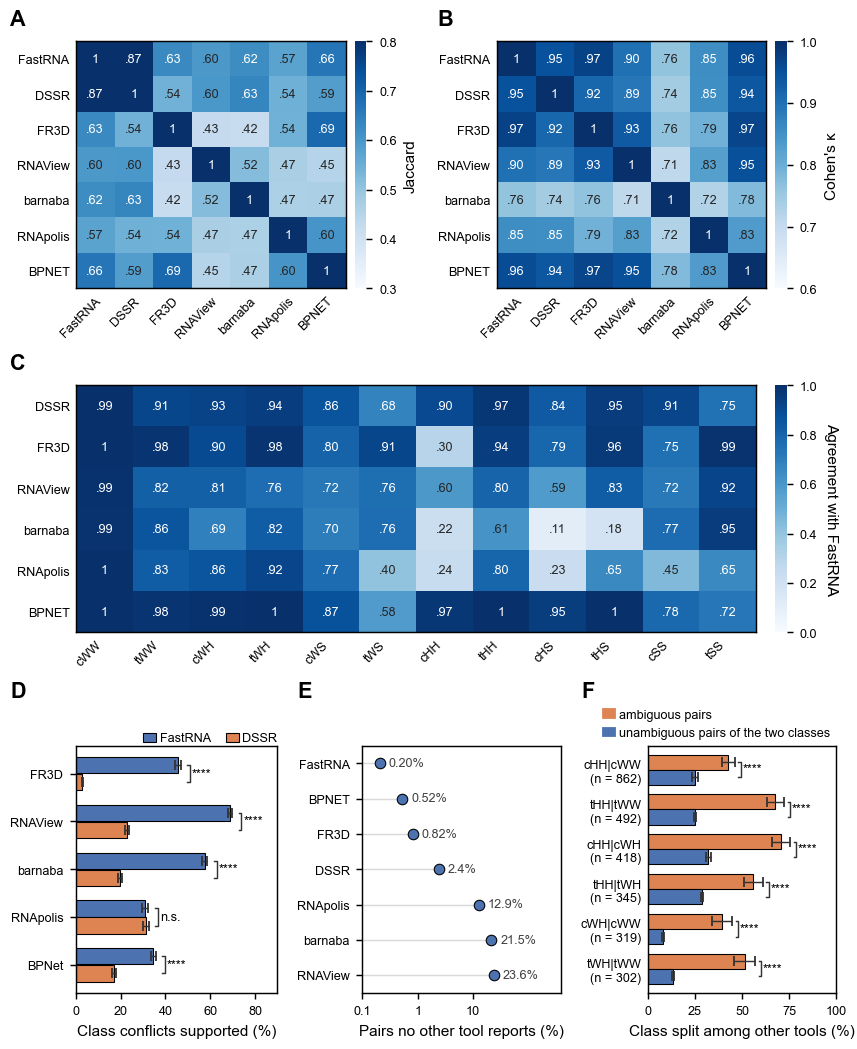

In [10]:
def restack_rows(fig, rows, gap_in=0.25, margin_in=0.05):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches()
    ft = lambda y_px: H - y_px / fig.dpi
    tops = [min(ft(a.get_tightbbox(r).y1) for a in row) for row in rows]
    bots = [max(ft(a.get_tightbbox(r).y0) for a in row) for row in rows]

    def row_of(y_ft):
        below = [i for i in range(len(rows)) if y_ft <= bots[i]]
        return min(below, key=lambda i: abs(tops[i] - y_ft)) if below else len(rows) - 1

    texts = [(t, row_of(ft(t.get_window_extent(r).y0))) for t in fig.texts]
    for t, i in texts:
        e = t.get_window_extent(r)
        tops[i], bots[i] = min(tops[i], ft(e.y1)), max(bots[i], ft(e.y0))
    gaps = list(gap_in) if np.iterable(gap_in) else [gap_in] * (len(rows) - 1)
    deltas, cursor = [], margin_in
    for i, (top, bot) in enumerate(zip(tops, bots)):
        deltas.append(cursor - top)
        cursor += bot - top + (gaps[i] if i < len(gaps) else 0)
    H2 = cursor + margin_in
    fig.set_size_inches(W, H2)
    conv = lambda y_frac, d: (H2 - (H - y_frac * H + d)) / H2
    for i, row in enumerate(rows):
        for a in row:
            p = a.get_position(original=True)
            a.set_position([p.x0, conv(p.y0, deltas[i]), p.width, p.height * H / H2],
                           which="both")
    for t, i in texts:
        x, y = t.get_position()
        t.set_position((x, conv(y, deltas[i])))


TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


plt.rcParams.update({"xtick.labelsize": 7, "ytick.labelsize": 7, "axes.labelsize": 8,
                     "legend.fontsize": 7})
FIG_W, FIG_H = 6.65, 14.0
LABEL_IN, COL_W, GUTTER = 0.70, 2.55, 0.75
X1, X2 = LABEL_IN, LABEL_IN + COL_W + GUTTER
FULL_W = X2 + COL_W - X1
PLOT_H = 1.9
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
HM_W, CBAR_PAD, CBAR_W = COL_W - 0.62, 0.07, 0.09
cbar_side = lambda ax: fig.add_axes([ax.get_position().x1 + CBAR_PAD / FIG_W, ax.get_position().y0,
                                     CBAR_W / FIG_W, ax.get_position().height])

ax_a = fig.add_axes(inch(X1, 0.6, HM_W, PLOT_H))
ax_b = fig.add_axes(inch(X2, 0.6, HM_W, PLOT_H))
ax_c = fig.add_axes(inch(X1, 4.6, FULL_W - 0.62, PLOT_H))
cax_c = fig.add_axes(inch(X1 + FULL_W - 0.47, 4.6, 0.09, PLOT_H))
D_W, E_W, F_W = 1.55, 1.15, 1.45
E_X = X1 + D_W + 0.80
F_X = E_X + E_W + 0.90
ax_d = fig.add_axes(inch(X1, 8.2, D_W, PLOT_H))
ax_e = fig.add_axes(inch(E_X, 8.2, E_W, PLOT_H))
ax_f = fig.add_axes(inch(F_X, 8.2, F_W, PLOT_H))
cax_a, cax_b = cbar_side(ax_a), cbar_side(ax_b)

draw_a(ax_a, fig, cax_a)
draw_b(ax_b, fig, cax_b)
cax_a.set_ylabel("Jaccard")
cax_b.set_ylabel("Cohen's \u03ba")
cax_b.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0], ["0.6", "0.7", "0.8", "0.9", "1.0"])
for ax in (ax_a, ax_b):
    ax.tick_params(axis="x", labelrotation=45)
    for t in ax.get_xticklabels():
        t.set_ha("right")
        t.set_rotation_mode("anchor")
draw_c(ax_c, fig, cax_c)
ax_a.set_aspect("auto"); ax_b.set_aspect("auto")
ax_c.set_aspect("auto")
draw_d(ax_d, compact=True)
draw_e(ax_e, compact=True)
draw_f(ax_f, compact=True)
set_uniform_text(fig)
enlarge_axis_labels(fig)


def fill_top_row(gap_in=0.15):
    for _ in range(4):
        fig.canvas.draw()
        r, to_fig = fig.canvas.get_renderer(), fig.transFigure.inverted()
        bb = lambda *axes: [a.get_tightbbox(r).transformed(to_fig) for a in axes]
        a_right = max(b.x1 for b in bb(ax_a, cax_a))
        b_left = min(b.x0 for b in bb(ax_b, cax_b))
        b_right = max(b.x1 for b in bb(ax_b, cax_b))
        target = max(b.x1 for b in bb(ax_c, cax_c))
        slack = (b_left - a_right - gap_in / FIG_W) + (target - b_right)
        if abs(slack) * FIG_W < 0.005:
            break
        grow = slack / 2
        pa, pb = ax_a.get_position(), ax_b.get_position()
        ax_a.set_position([pa.x0, pa.y0, pa.width + grow, pa.height])
        shift = (a_right + grow + gap_in / FIG_W) - b_left
        ax_b.set_position([pb.x0 + shift, pb.y0, pb.width + grow, pb.height])
        for ax, cax in ((ax_a, cax_a), (ax_b, cax_b)):
            q = ax.get_position()
            cax.set_position([q.x1 + CBAR_PAD / FIG_W, q.y0, CBAR_W / FIG_W, q.height])


fill_top_row()


def fill_bottom_row(gap_in=0.15):
    """Widen E so the gaps D-to-E and E-to-F (frame or labels, whichever is nearer) are gap_in."""
    for _ in range(4):
        fig.canvas.draw()
        r, to_fig = fig.canvas.get_renderer(), fig.transFigure.inverted()
        tb = lambda a: a.get_tightbbox(r).transformed(to_fig)
        pe = ax_e.get_position()
        e_left_labels = pe.x0 - tb(ax_e).x0
        x0 = tb(ax_d).x1 + gap_in / FIG_W + e_left_labels
        x1 = tb(ax_f).x0 - gap_in / FIG_W - (tb(ax_e).x1 - pe.x1)
        if abs(x0 - pe.x0) * FIG_W < 0.005 and abs(x1 - pe.x1) * FIG_W < 0.005:
            break
        ax_e.set_position([x0, pe.y0, x1 - x0, pe.height])


fill_bottom_row()

MARGIN_L = 0.012
inv = fig.transFigure.inverted()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
box = lambda *axes: [a.get_tightbbox(renderer).transformed(inv) for a in axes]
left = min(b.x0 for b in box(ax_a, ax_c, ax_d))
for group, s in (((ax_a, cax_a), "A"), ((ax_b, cax_b), "B"), ((ax_c, cax_c), "C"),
                 ((ax_d,), "D"), ((ax_e,), "E"), ((ax_f,), "F")):
    bb = box(*group)
    x = left if s in "ACD" else min(b.x0 for b in bb)
    y = max(b.y1 for b in box(ax_d, ax_e, ax_f)) if s in "DEF" else max(b.y1 for b in bb)
    fig.text(x, y + 0.004, s, fontsize=LETTER_PT, fontweight="bold",
             ha="left", va="bottom")

restack_rows(fig, [[ax_a, cax_a, ax_b, cax_b], [ax_c, cax_c], [ax_d, ax_e, ax_f]],
             gap_in=[0.10, 0.10])
seat_legend(ax_d)

def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)

def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

save(fig, "figures/supplemental/figS2.png")
plt.show()
